In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from src.data import (load_data, deduplicate, FEATURE_COLS, NUMERIC_COLS, CATEGORICAL_COLS, FEATURE_GROUPS,
                      CLASS_ORDER, TARGET, RESULTS_DIR)
from src.plotting import use_style, save, SERIES, DIVERGING

use_style()
train, test = load_data()
print(train.shape, test.shape)
print(train.dtypes.astype(str).value_counts().to_dict())
print(train.isna().sum().sum(), test.isna().sum().sum())

(175341, 45) (82332, 45)
{'int64': 30, 'float64': 11, 'str': 4}
0 0


                train   test  train_share  test_share
attack_cat                                           
Normal          56000  37000       0.3194      0.4494
Generic         40000  18871       0.2281      0.2292
Exploits        33393  11132       0.1904      0.1352
Fuzzers         18184   6062       0.1037      0.0736
DoS             12264   4089       0.0699      0.0497
Reconnaissance  10491   3496       0.0598      0.0425
Analysis         2000    677       0.0114      0.0082
Backdoor         1746    583       0.0100      0.0071
Shellcode        1133    378       0.0065      0.0046
Worms             130     44       0.0007      0.0005
430.8


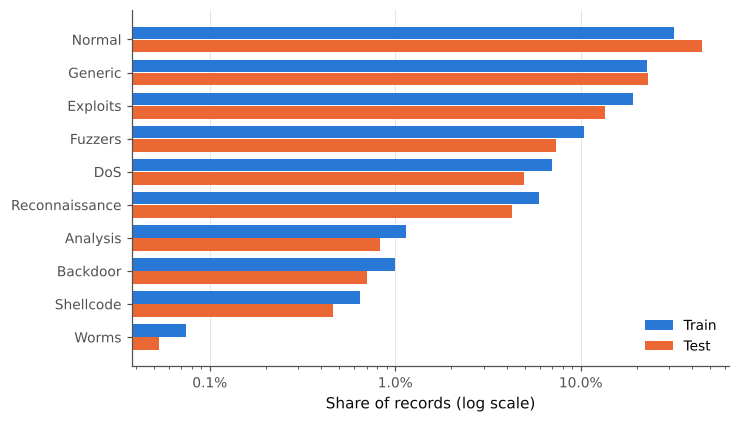

In [2]:
counts = pd.DataFrame({"train": train[TARGET].value_counts(), "test": test[TARGET].value_counts()}).loc[CLASS_ORDER]
shares = counts / counts.sum()
class_table = counts.join(shares.add_suffix("_share"))
class_table.to_csv(RESULTS_DIR / "01_class_distribution.csv")
print(class_table.round(4))
print(round(counts["train"].max() / counts["train"].min(), 1))

positions = np.arange(len(CLASS_ORDER))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(positions - 0.2, shares["train"], height=0.38, color=SERIES[0], label="Train")
ax.barh(positions + 0.2, shares["test"], height=0.38, color=SERIES[1], label="Test")
ax.set_yticks(positions, CLASS_ORDER)
ax.invert_yaxis()
ax.set_xscale("log")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_xlabel("Share of records (log scale)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, "01_class_distribution.png")
plt.show()

label               0      1
attack_cat                  
Normal          56000      0
Generic             0  40000
Exploits            0  33393
Fuzzers             0  18184
DoS                 0  12264
Reconnaissance      0  10491
Analysis            0   2000
Backdoor            0   1746
Shellcode           0   1133
Worms               0    130
                   min     max
attack_cat                    
Normal               1  115964
Generic         117205  175341
Exploits         48933  175306
Fuzzers          48018  175002
DoS              49000  175249
Reconnaissance   48867  175180
Analysis         47933  172533
Backdoor         47912  174021
Shellcode        48814  175338
Worms            49960  168944


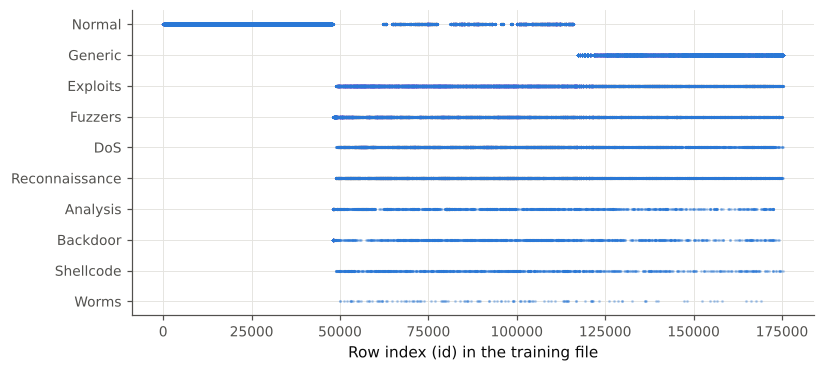

In [3]:
print(pd.crosstab(train[TARGET], train["label"]).loc[CLASS_ORDER])
id_range = train.groupby(TARGET)["id"].agg(["min", "max"]).loc[CLASS_ORDER]
id_range.to_csv(RESULTS_DIR / "01_id_range_by_class.csv")
print(id_range)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(train["id"], train[TARGET].map({c: i for i, c in enumerate(CLASS_ORDER)}),
           s=1, alpha=0.25, color=SERIES[0], rasterized=True)
ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
ax.invert_yaxis()
ax.set_xlabel("Row index (id) in the training file")
save(fig, "01_id_by_class.png")
plt.show()

train_records              175341
repeated_feature_rows       74301
contradictory_rows          30528
removed_by_dedup            67601
records_after_dedup        107740
test_rows_seen_in_train      8541
test_records                82332
dtype: int64
                records  repeated_share  contradictory_share  \
attack_cat                                                     
Normal            56000           0.075                0.007   
Generic           40000           0.902                0.008   
Exploits          33393           0.439                0.398   
Fuzzers           18184           0.181                0.114   
DoS               12264           0.755                0.795   
Reconnaissance    10491           0.388                0.180   
Analysis           2000           0.729                0.720   
Backdoor           1746           0.706                0.767   
Shellcode          1133           0.039                0.006   
Worms               130           0.069      

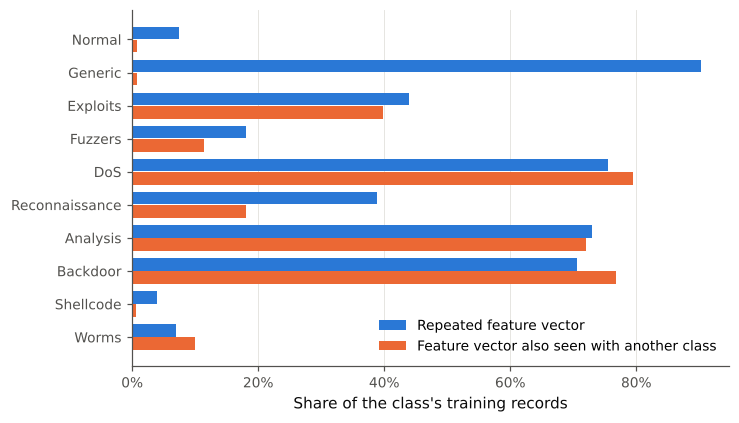

In [4]:
repeated = train.duplicated(subset=FEATURE_COLS)
contradictory = train.groupby(FEATURE_COLS)[TARGET].transform("nunique") > 1
deduped = deduplicate(train)
overlap = test[FEATURE_COLS].merge(train[FEATURE_COLS].drop_duplicates(), how="inner")
class_counts = train[TARGET].value_counts()
duplicates = pd.DataFrame({
    "records": class_counts,
    "repeated_share": train.loc[repeated, TARGET].value_counts() / class_counts,
    "contradictory_share": train.loc[contradictory, TARGET].value_counts() / class_counts,
    "records_after_dedup": deduped[TARGET].value_counts(),
}).loc[CLASS_ORDER].fillna(0)
duplicates.to_csv(RESULTS_DIR / "01_duplicates_by_class.csv")
duplicate_summary = pd.Series({
    "train_records": len(train),
    "repeated_feature_rows": int(repeated.sum()),
    "contradictory_rows": int(contradictory.sum()),
    "removed_by_dedup": len(train) - len(deduped),
    "records_after_dedup": len(deduped),
    "test_rows_seen_in_train": len(overlap),
    "test_records": len(test),
})
duplicate_summary.to_csv(RESULTS_DIR / "01_duplicates_summary.csv", header=["value"])
print(duplicate_summary)
print(duplicates.round(3))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(positions - 0.2, duplicates["repeated_share"], height=0.38, color=SERIES[0], label="Repeated feature vector")
ax.barh(positions + 0.2, duplicates["contradictory_share"], height=0.38, color=SERIES[1],
        label="Feature vector also seen with another class")
ax.set_yticks(positions, CLASS_ORDER)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Share of the class's training records")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, "01_duplicates_by_class.png")
plt.show()

trans_depth          167.3
response_body_len     76.3
sbytes                45.3
sloss                 44.8
dloss                 41.4
spkts                 40.2
dbytes                39.8
dpkts                 36.8
dinpkt                29.7
djit                  29.5
Name: skew, dtype: float64
False


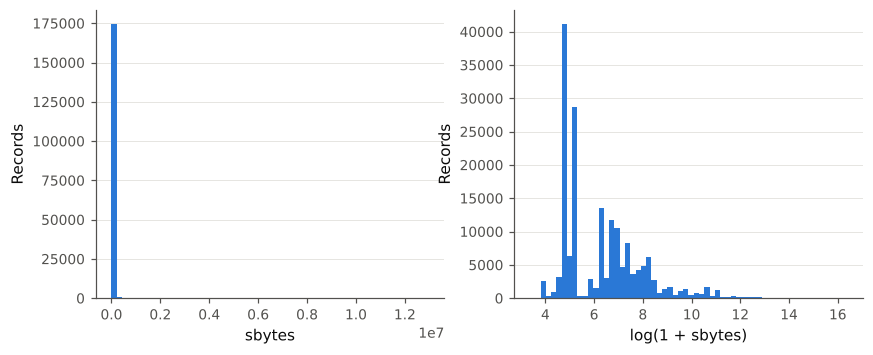

In [5]:
numeric_summary = train[NUMERIC_COLS].describe().T
numeric_summary["skew"] = train[NUMERIC_COLS].skew()
numeric_summary.to_csv(RESULTS_DIR / "01_numeric_summary.csv")
print(numeric_summary["skew"].sort_values(ascending=False).head(10).round(1))
print((train[NUMERIC_COLS] < 0).any().any())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].hist(train["sbytes"], bins=60, color=SERIES[0])
axes[0].set_xlabel("sbytes")
axes[1].hist(np.log1p(train["sbytes"]), bins=60, color=SERIES[0])
axes[1].set_xlabel("log(1 + sbytes)")
for ax in axes:
    ax.set_ylabel("Records")
    ax.grid(axis="x", visible=False)
save(fig, "01_log_transform.png")
plt.show()

is_ftp_login      ct_ftp_cmd          1.000
dbytes            dloss               0.997
sbytes            sloss               0.996
swin              dwin                0.990
ct_srv_src        ct_srv_dst          0.980
dpkts             dloss               0.979
ct_srv_dst        ct_dst_src_ltm      0.972
dpkts             dbytes              0.972
spkts             sloss               0.971
ct_srv_src        ct_dst_src_ltm      0.967
spkts             sbytes              0.964
ct_dst_ltm        ct_src_dport_ltm    0.962
tcprtt            synack              0.949
                  ackdat              0.942
sinpkt            is_sm_ips_ports     0.941
ct_src_dport_ltm  ct_dst_sport_ltm    0.907
Name: r, dtype: float64
0.232 {'sbytes': -0.021, 'dbytes': -0.136, 'spkts': -0.103, 'dpkts': -0.193}


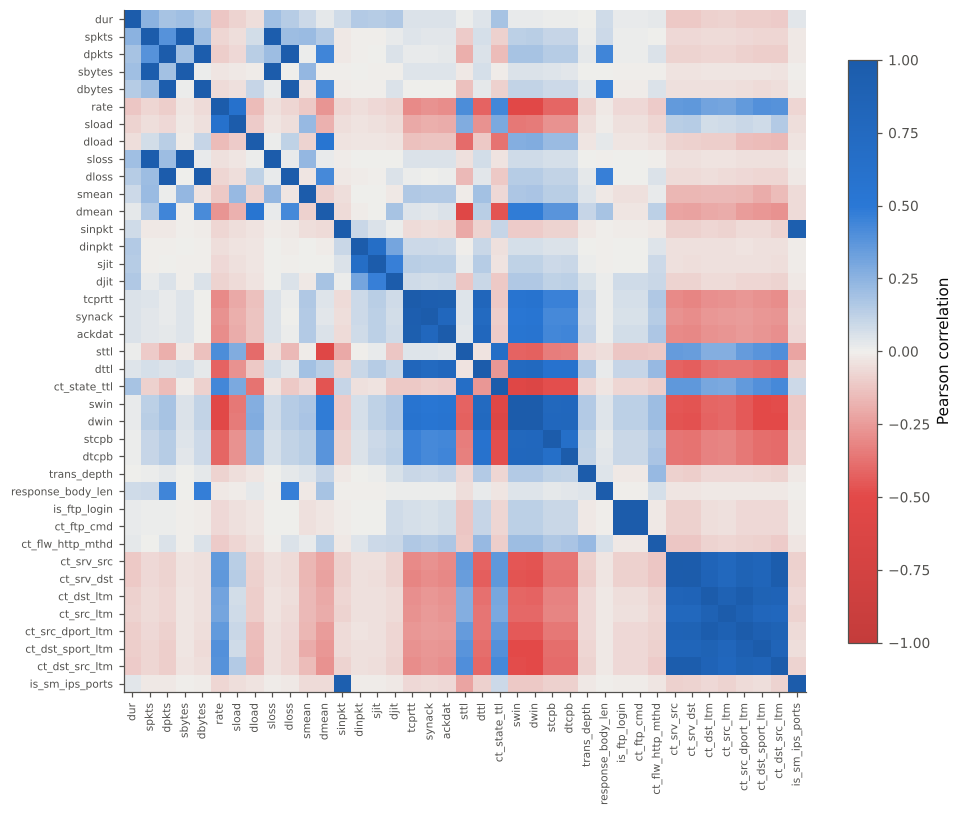

In [6]:
corr = train[NUMERIC_COLS].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.9].sort_values(key=np.abs, ascending=False).rename("r")
strong.to_csv(RESULTS_DIR / "01_high_correlations.csv")
print(strong.round(3))
print(round(corr.loc["sbytes", "smean"], 3), corr.loc["sttl", ["sbytes", "dbytes", "spkts", "dpkts"]].round(3).to_dict())

fig, ax = plt.subplots(figsize=(10, 8.6))
image = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(NUMERIC_COLS)), NUMERIC_COLS, rotation=90, fontsize=7)
ax.set_yticks(range(len(NUMERIC_COLS)), NUMERIC_COLS, fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.8, label="Pearson correlation")
save(fig, "01_correlation.png")
plt.show()

In [7]:
categorical_summary = pd.DataFrame({
    col: {"categories_train": train[col].nunique(),
          "categories_below_10_records": int((train[col].value_counts() < 10).sum()),
          "test_only_categories": ", ".join(sorted(set(test[col]) - set(train[col])))}
    for col in CATEGORICAL_COLS}).T
categorical_summary.to_csv(RESULTS_DIR / "01_categorical_summary.csv")
print(categorical_summary)
service_by_class = (pd.crosstab(train["service"], train[TARGET], normalize="columns")[CLASS_ORDER] * 100).round(1)
service_by_class.to_csv(RESULTS_DIR / "01_service_by_class.csv")
service_by_class

        categories_train categories_below_10_records test_only_categories
proto                133                           1                     
service               13                           0                     
state                  9                           3             ACC, CLO


attack_cat,Normal,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
service,,,,,,,,,,
dhcp,0.0,0.0,0.2,0.0,0.3,0.0,0.0,0.0,0.0,0.0
dns,13.4,97.8,0.6,2.0,0.9,0.3,0.0,0.0,0.0,0.0
ftp,2.2,0.0,4.8,3.0,0.4,0.0,0.0,0.3,0.0,0.0
ftp-data,4.6,0.0,4.3,0.0,0.1,0.0,0.0,0.0,0.0,0.0
http,9.6,0.7,26.0,4.6,9.9,15.3,27.9,4.8,0.0,87.7
irc,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.6,0.0,0.0
none,65.2,1.3,51.5,90.5,85.4,83.8,71.8,94.3,100.0,12.3
pop3,0.0,0.0,3.1,0.0,0.5,0.0,0.0,0.0,0.0,0.0
radius,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
ttl_counts = train["sttl"].value_counts()
top_ttl = ttl_counts.head(6).index
sttl_by_class = (pd.crosstab(train["sttl"], train[TARGET], normalize="index").loc[top_ttl, CLASS_ORDER] * 100).round(1)
sttl_by_class.insert(0, "records", ttl_counts.loc[top_ttl])
sttl_by_class.to_csv(RESULTS_DIR / "01_sttl_by_class.csv")
sttl_by_class

attack_cat,records,Normal,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
sttl,,,,,,,,,,,
254,114743,9.8,34.7,17.3,15.8,9.5,9.1,1.3,1.5,1.0,0.1
31,39455,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
62,17681,12.3,1.3,75.5,0.3,7.1,0.2,3.1,0.2,0.0,0.0
0,3162,90.4,0.1,5.4,0.5,2.3,0.8,0.1,0.5,0.0,0.0
64,181,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,64,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
ttl_shift = pd.DataFrame({
    f"{split}_{cls}": df.loc[df[TARGET] == cls, "sttl"].value_counts(normalize=True)
    for split, df in [("train", train), ("test", test)] for cls in ["Normal", "Fuzzers"]
}).fillna(0).loc[[31, 254, 62, 0]]
ttl_shift.to_csv(RESULTS_DIR / "01_sttl_shift.csv")
(ttl_shift * 100).round(1)

,train_Normal,train_Fuzzers,test_Normal,test_Fuzzers
sttl,,,,
31,70.5,0.0,45.1,0.0
254,20.1,99.6,40.7,99.8
62,3.9,0.3,11.2,0.0
0,5.1,0.1,2.7,0.0


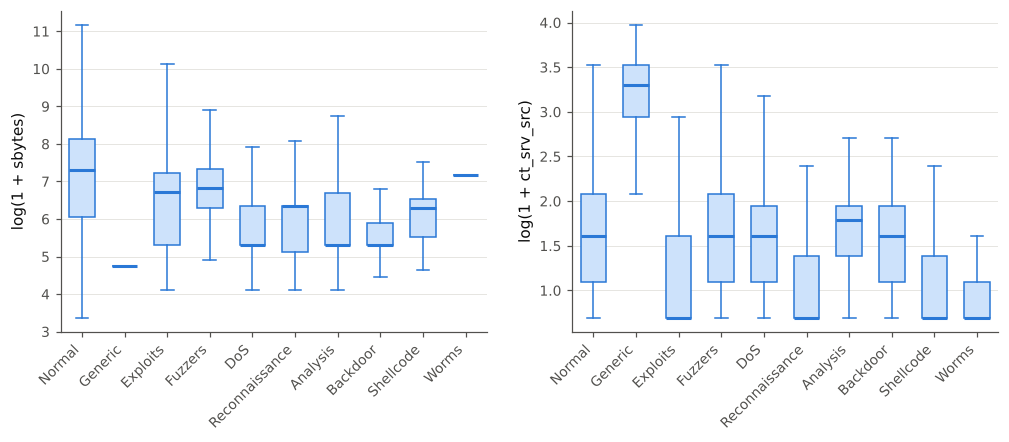

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, feature in zip(axes, ["sbytes", "ct_srv_src"]):
    values = [np.log1p(train.loc[train[TARGET] == c, feature]) for c in CLASS_ORDER]
    ax.boxplot(values, showfliers=False, patch_artist=True, widths=0.6,
               boxprops={"facecolor": "#cde2fb", "edgecolor": SERIES[0]},
               medianprops={"color": SERIES[0], "linewidth": 2},
               whiskerprops={"color": SERIES[0]}, capprops={"color": SERIES[0]})
    ax.set_xticks(range(1, len(CLASS_ORDER) + 1), CLASS_ORDER, rotation=45, ha="right")
    ax.set_ylabel(f"log(1 + {feature})")
    ax.grid(axis="x", visible=False)
save(fig, "01_features_by_class.png")
plt.show()

In [11]:
feature_groups = pd.DataFrame(
    [(group, len(cols), ", ".join(cols)) for group, cols in FEATURE_GROUPS.items()]
    + [("categorical", len(CATEGORICAL_COLS), ", ".join(CATEGORICAL_COLS))],
    columns=["group", "n_features", "features"])
feature_groups.to_csv(RESULTS_DIR / "01_feature_groups.csv", index=False)
feature_groups

,group,n_features,features
0,volume,12,"dur, spkts, dpkts, sbytes, dbytes, rate, sload..."
1,timing,7,"sinpkt, dinpkt, sjit, djit, tcprtt, synack, ac..."
2,ttl,3,"sttl, dttl, ct_state_ttl"
3,tcp_header,4,"swin, dwin, stcpb, dtcpb"
4,app_content,5,"trans_depth, response_body_len, is_ftp_login, ..."
5,conn_history,8,"ct_srv_src, ct_srv_dst, ct_dst_ltm, ct_src_ltm..."
6,categorical,3,"proto, service, state"
